<a href="https://colab.research.google.com/github/jelianeys21/banderas-colores/blob/main/S5_PDDIYVA_umbral-contrste-brillo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as  np
import matplotlib.pyplot as plt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  6548  100  6548    0     0   177k      0 --:--:-- --:--:-- --:--:--  177k


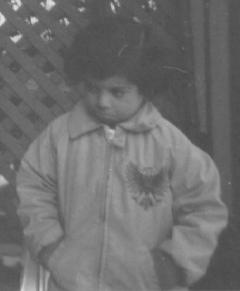

In [ ]:
!curl -o imagen https://raw.githubusercontent.com/giancarlo92/curso_pdi/main/imagenes/clase5/pout.jpg
persona = cv2.imread("imagen")
persona_gris = cv2.cvtColor(persona, cv2.COLOR_BGR2GRAY)
cv2_imshow(persona_gris)

In [ ]:
!git clone https://github.com/giancarlo92/curso_pdi

Cloning into 'curso_pdi'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 34 (delta 4), reused 22 (delta 1), pack-reused 0
Unpacking objects: 100% (34/34), done.


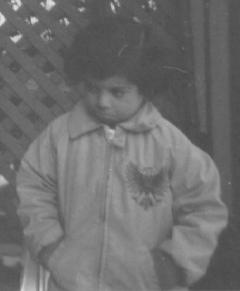

In [ ]:
img = cv2.imread("/content/curso_pdi/imagenes/clase5/pout.jpg")
cv2_imshow(img)

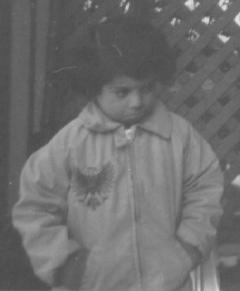

In [ ]:
from curso_pdi.funciones.reflejar import reflejar_imagen
reflejo = reflejar_imagen(persona_gris)
cv2_imshow(reflejo)

**BRILLO**

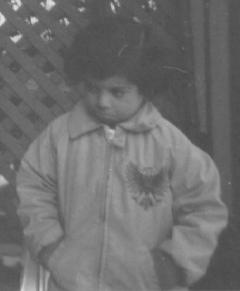

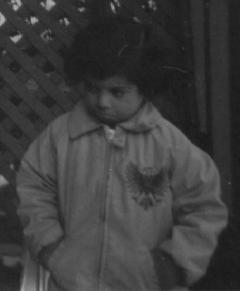

In [ ]:
(f, c) = persona_gris.shape
factor_correccion = -50
persona_brillo = np.zeros((f, c))
for i in range(0, f):
  for j in range(0, c):
    persona_brillo[i][j] = persona_gris[i][j] + factor_correccion
    if persona_brillo[i][j] > 255:
      persona_brillo[i][j] = 255
    elif persona_brillo[i][j] < 0:
      persona_brillo[i][j] = 0
persona_brillo = persona_brillo.astype(np.uint8)
cv2_imshow(persona_gris)
cv2_imshow(persona_brillo)

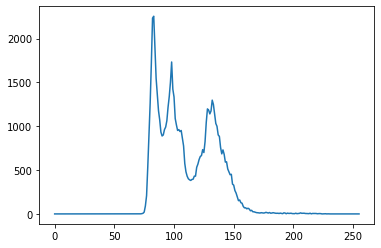

In [ ]:
from curso_pdi.funciones.histograma import imagen_histograma
imagen_histograma(persona_gris)

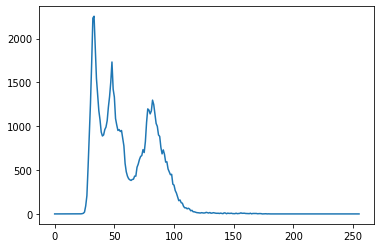

In [ ]:
imagen_histograma(persona_brillo)

**CONTRASTE**

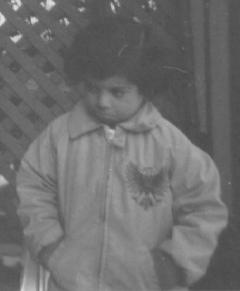

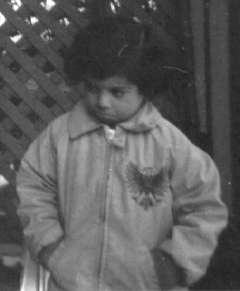

In [ ]:
(f, c) = persona_gris.shape
persona_contraste = np.zeros((f, c))
maximo = persona_gris.max()
minimo = persona_gris.min()
for i in range(0, f):
  for j in range(0, c):
    pixel_actual = persona_gris[i][j]
    persona_contraste[i][j] = round(((pixel_actual - minimo) / (maximo - minimo)) * 255)
    persona_contraste[i][j] = persona_contraste[i][j] + 30
    if persona_contraste[i][j] > 255:
      persona_contraste[i][j] = 255
    elif persona_contraste[i][j] < 0:
      persona_contraste[i][j] = 0
persona_contraste = persona_contraste.astype(np.uint8)
cv2_imshow(persona_gris)
cv2_imshow(persona_contraste)

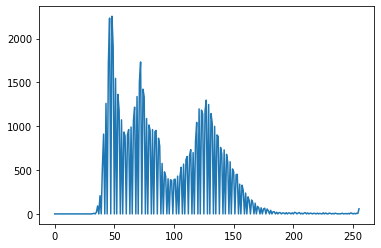

In [ ]:
imagen_histograma(persona_contraste)

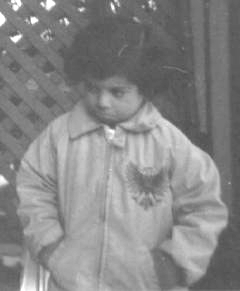

In [ ]:
# OPENCV
alpha = 1.5 # Controla el contraste (1.0 - 3.0)
beta = -30 # Controla el brillo (-100 a 100)
imagen_nueva = cv2.convertScaleAbs(persona_gris, alpha=alpha, beta=beta)
cv2_imshow(imagen_nueva)

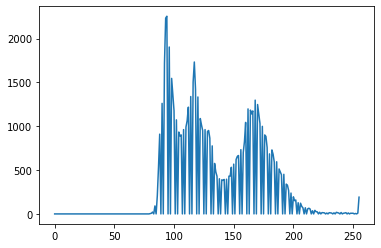

In [ ]:
imagen_histograma(imagen_nueva)

**GAMMA**

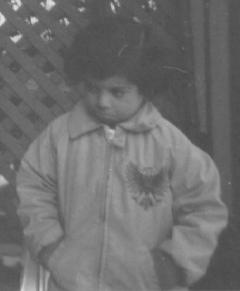

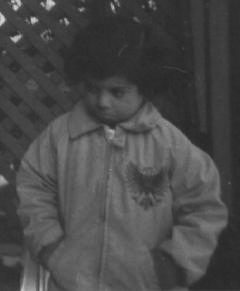

In [ ]:
(f, c) = persona_gris.shape
persona_gamma = np.zeros((f, c))
Y = 1.5 #0.0 - 5.0, 1 = valor original
for i in range(0, f):
  for j in range(0, c):
    persona_gamma[i][j] = 255*((persona_gris[i][j]/255)**Y)
persona_gamma = persona_gamma.astype(np.uint8)
cv2_imshow(persona_gris)
cv2_imshow(persona_gamma)

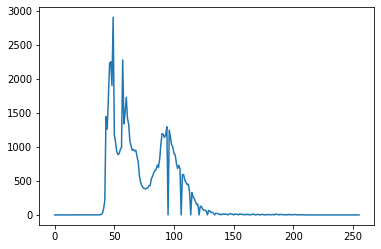

In [ ]:
imagen_histograma(persona_gamma)

**NEGATIVO**

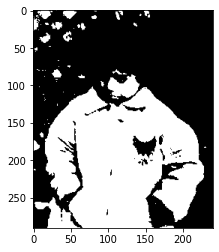

In [ ]:
UMBRAL = 110
persona_binaria = persona_gris > UMBRAL
plt.imshow(persona_binaria)
plt.gray()

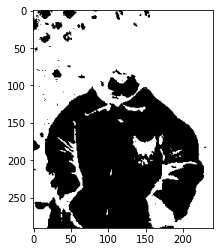

In [ ]:
persona_negativo = 1 - persona_binaria
plt.imshow(persona_negativo)

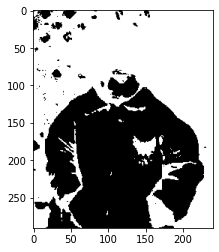

In [ ]:
UMBRAL = 110
persona_negativo2 = persona_gris < UMBRAL
plt.imshow(persona_negativo2)

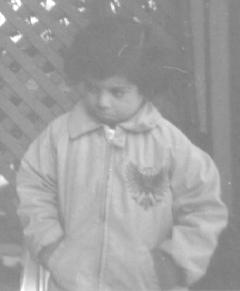

In [ ]:
from curso_pdi.funciones.brillo import brillo
imagen_brillo = brillo(persona_gris, 50)
cv2_imshow(imagen_brillo)

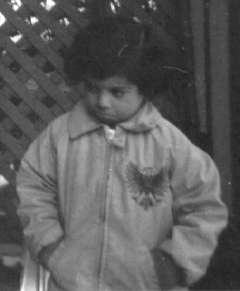

In [ ]:
from curso_pdi.funciones.contraste import contraste
imagen_contraste = contraste(persona_gris)
cv2_imshow(imagen_contraste)